In [11]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import transforms
from transformers import Dinov2Model
from transformers import AutoModel

In [2]:
# 1. Data Preprocessing
def preprocess_grz(image_grz):
    """Converts g/r/z composite to normalized RGB tensor."""
    transform = transforms.Compose([
        transforms.ToPILImage(),
        transforms.Resize((224, 224)), # Resize for the network
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # ImageNet normalization
    ])
    return transform(image_grz).unsqueeze(0)

In [3]:
# 2. DINO ViT-S/8 Attention Extraction
def get_dino_vits8_attention(model, x):
    """Extracts and upsamples CLS attention from DINO ViT-S/8."""
    attn = model.get_last_selfattention(x)  # [1, 6, 785, 785]
    cls_attn = attn[0, :, 0, 1:]            # Isolate CLS row, drop CLS col

    spatial_map = cls_attn.reshape(6, 28, 28) # Reshape to 28x28 grid
    upsampled = F.interpolate(
        spatial_map.unsqueeze(0),
        size=(224, 224),
        mode='nearest'
    ).squeeze(0) # Upsample via nearest-neighbour

    return upsampled

In [4]:
# 3. Naive Mask Generation (Per-Head)
def threshold_mask_per_head(attn_map, threshold=0.6):
    """Creates binary masks keeping 60% of attention mass independently for each head[cite: 2]."""
    masks = []
    for i in range(attn_map.shape[0]):
        head_map = attn_map[i]
        flat = head_map.flatten()
        sorted_vals, indices = torch.sort(flat, descending=True)
        cumulative = torch.cumsum(sorted_vals, dim=0)

        # Find cutoff index for 60% cumulative mass
        cutoff_idx = torch.searchsorted(cumulative, threshold * cumulative[-1])

        mask = torch.zeros_like(flat)
        mask[indices[:cutoff_idx + 1]] = 1
        masks.append(mask.reshape(head_map.shape))

    return torch.stack(masks)

In [5]:
# 4. DINOv2 Extraction
def get_dinov2_attention(hf_model, x):
    """Extracts attention using Hugging Face to leverage output_attentions=True without manual forward hooks[cite: 2]."""
    outputs = hf_model(x, output_attentions=True)
    last_layer_attn = outputs.attentions[-1] # [batch, heads, tokens, tokens]

    # Isolate CLS token attention
    cls_attn = last_layer_attn[0, :, 0, 1:]

    # Account for register tokens if present (ViT-S/14 yields a 16x16 grid = 256 patches)
    num_patches = 256
    cls_attn_patches = cls_attn[:, -num_patches:]

    spatial_map = cls_attn_patches.reshape(-1, 16, 16)
    upsampled = F.interpolate(
        spatial_map.unsqueeze(0),
        size=(224, 224),
        mode='nearest'
    ).squeeze(0)

    return upsampled

In [6]:
# 5. Visualization Pipeline
def visualize_task_a(image_rgb, attn_maps, masks):
    """Plots RGB | 6 head maps | combined mask for qualitative analysis[cite: 2]."""
    fig, axes = plt.subplots(1, 8, figsize=(20, 3))

    # De-normalize RGB for plotting
    inv_normalize = transforms.Normalize(
        mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
        std=[1/0.229, 1/0.224, 1/0.225]
    )
    img_plot = inv_normalize(image_rgb[0]).permute(1, 2, 0).clamp(0, 1)

    axes[0].imshow(img_plot.numpy())
    axes[0].set_title("RGB")
    axes[0].axis('off')

    # 6 Individual Attention Heads
    for i in range(6):
        axes[i+1].imshow(attn_maps[i].detach().cpu().numpy(), cmap='inferno')
        axes[i+1].set_title(f"Head {i+1}")
        axes[i+1].axis('off')

    # Composite Mask (Logical OR across all 6 heads)
    composite_mask = torch.max(masks, dim=0)[0]
    axes[7].imshow(composite_mask.detach().cpu().numpy(), cmap='gray')
    axes[7].set_title("Combined Mask")
    axes[7].axis('off')

    plt.tight_layout()
    plt.show()

Loading galaxy samples from gz10...
Running Task A attention inference...
--- Galaxy Sample 1 ---


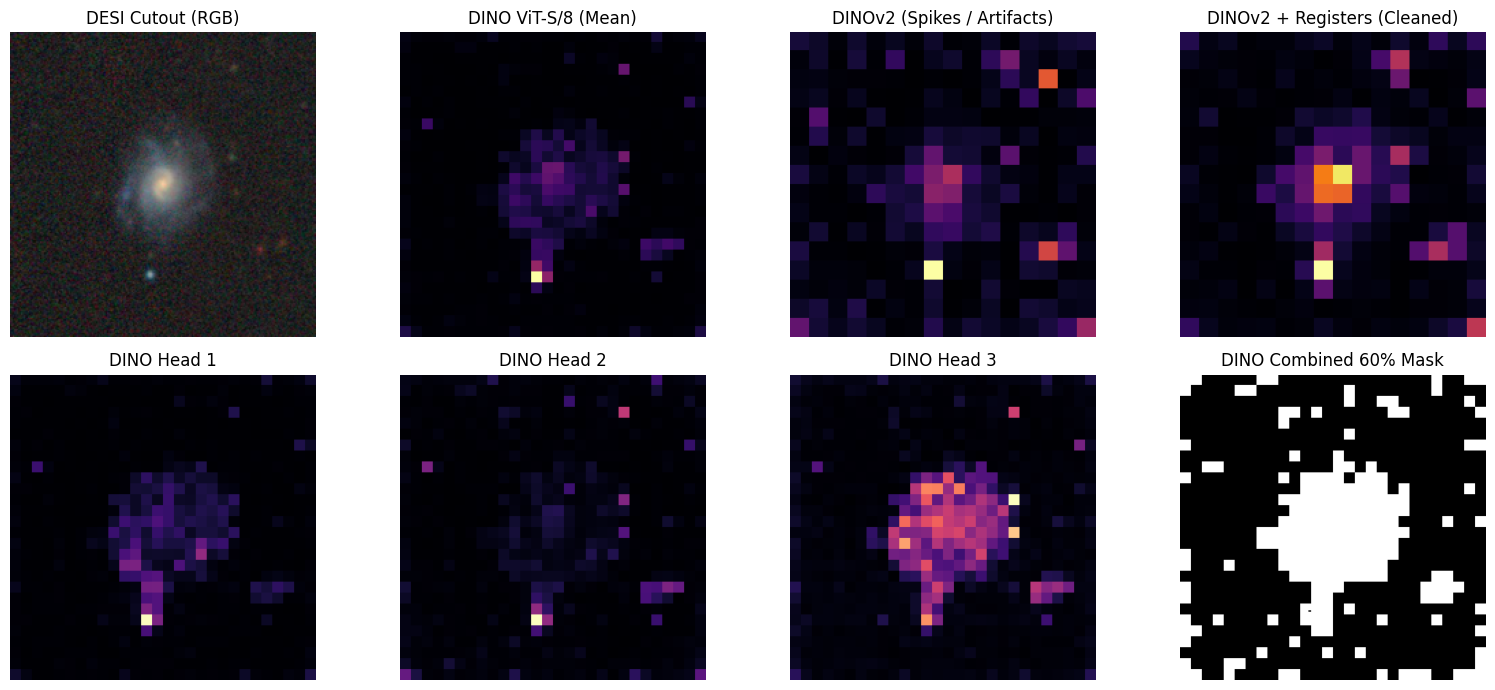

--- Galaxy Sample 2 ---


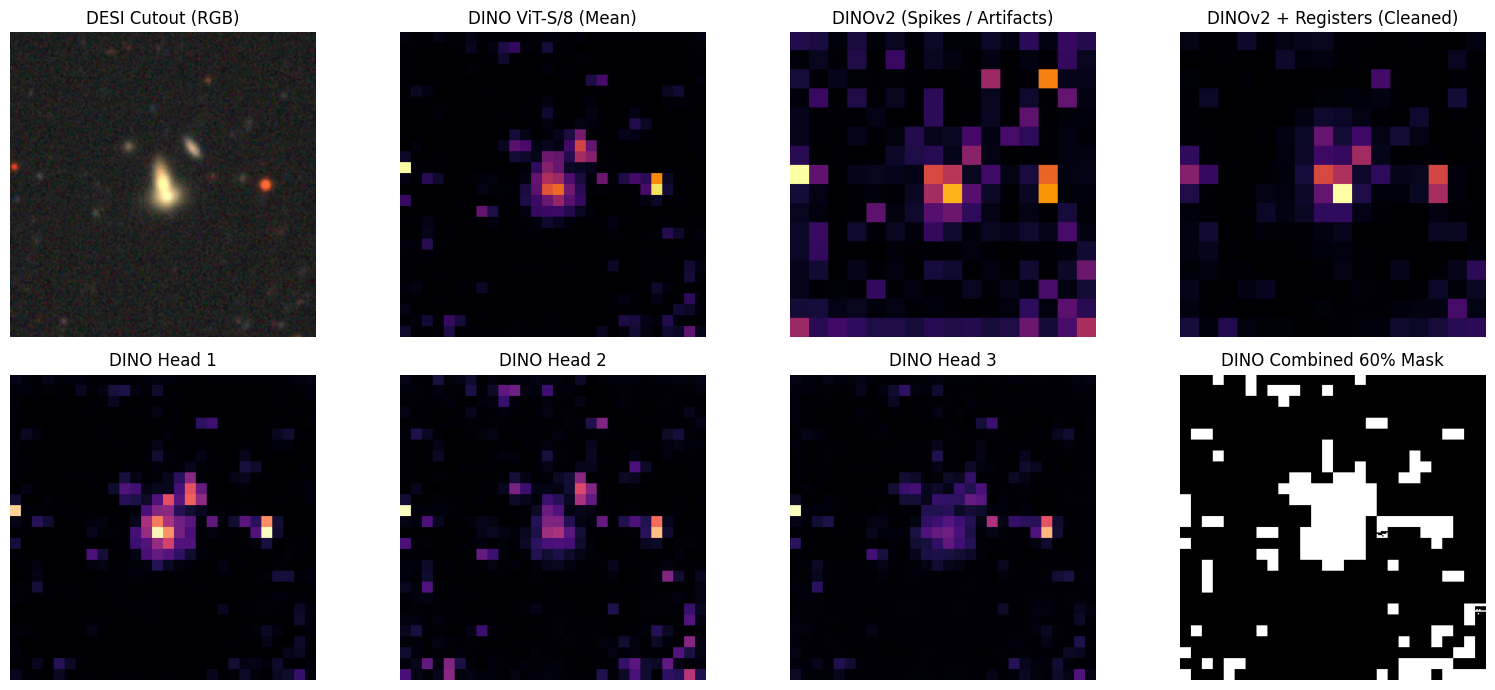

--- Galaxy Sample 3 ---


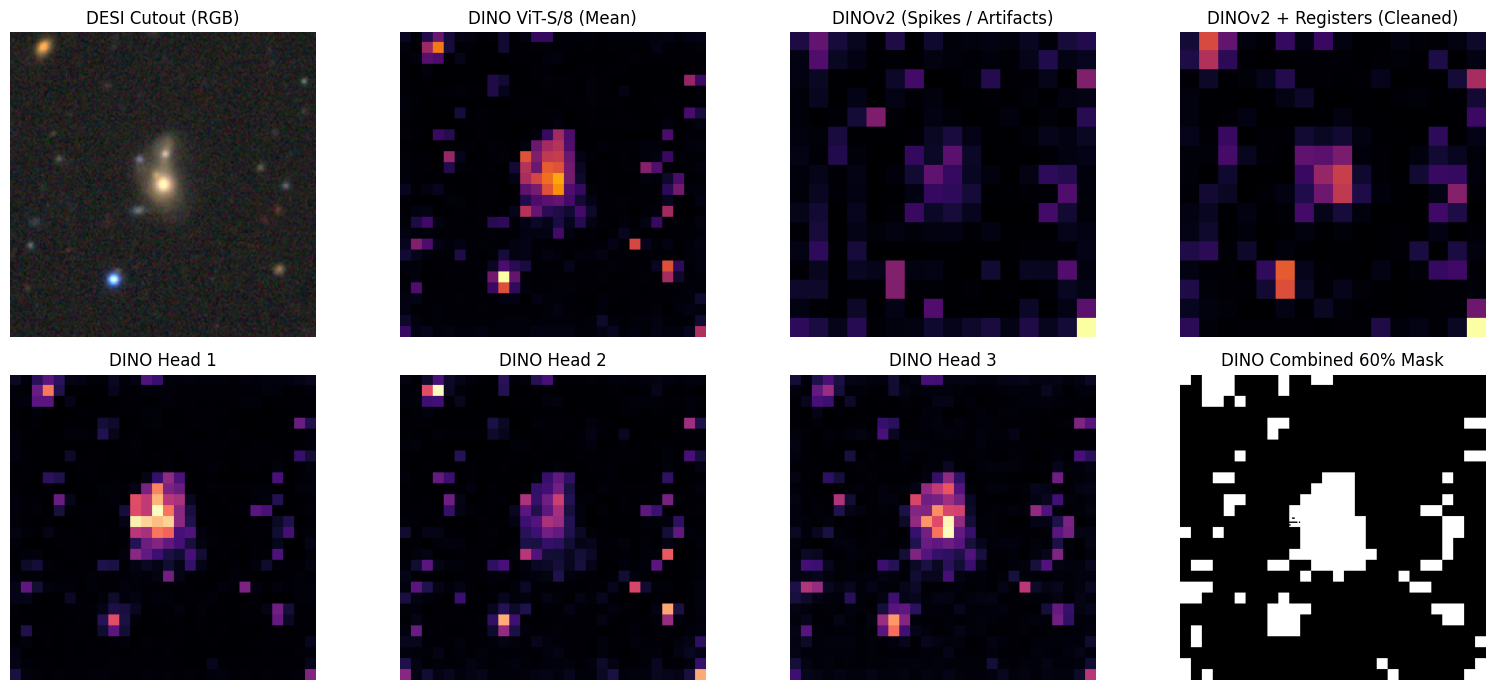

--- Galaxy Sample 4 ---


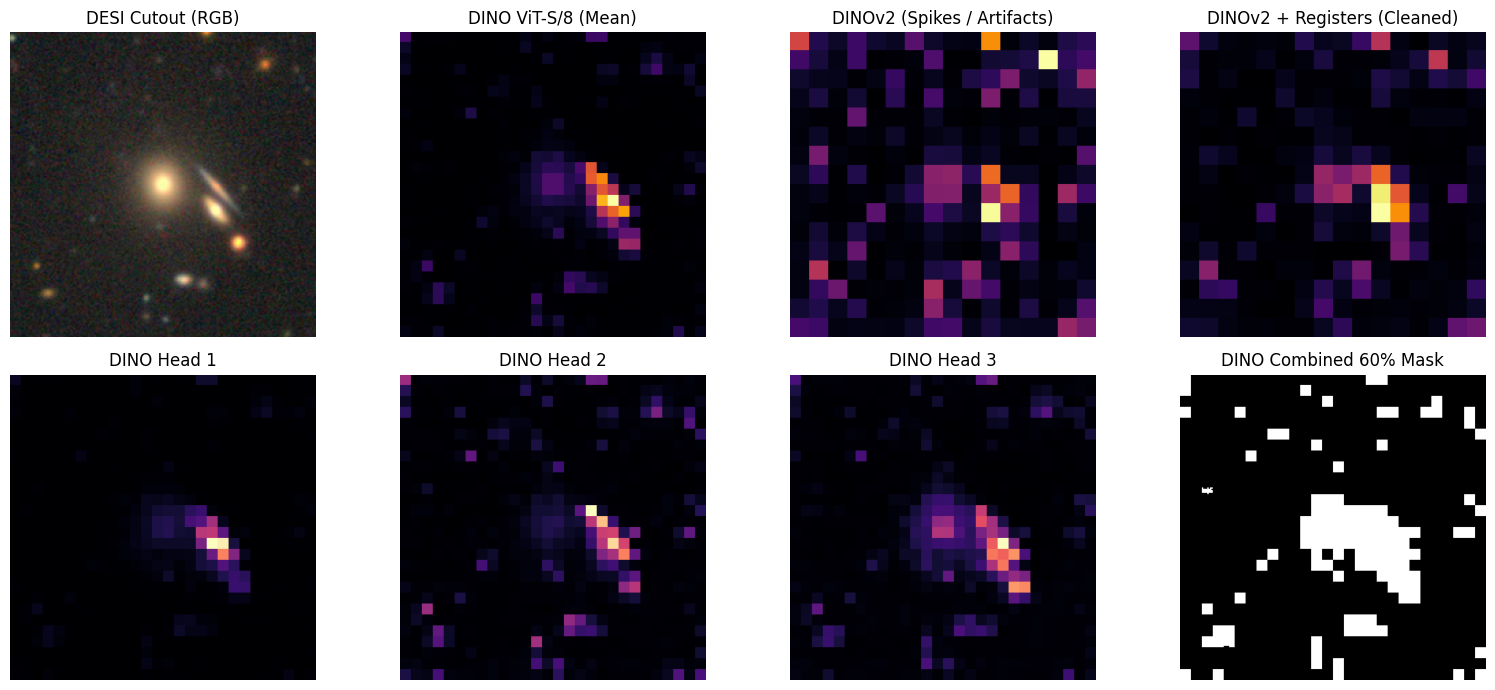

--- Galaxy Sample 5 ---


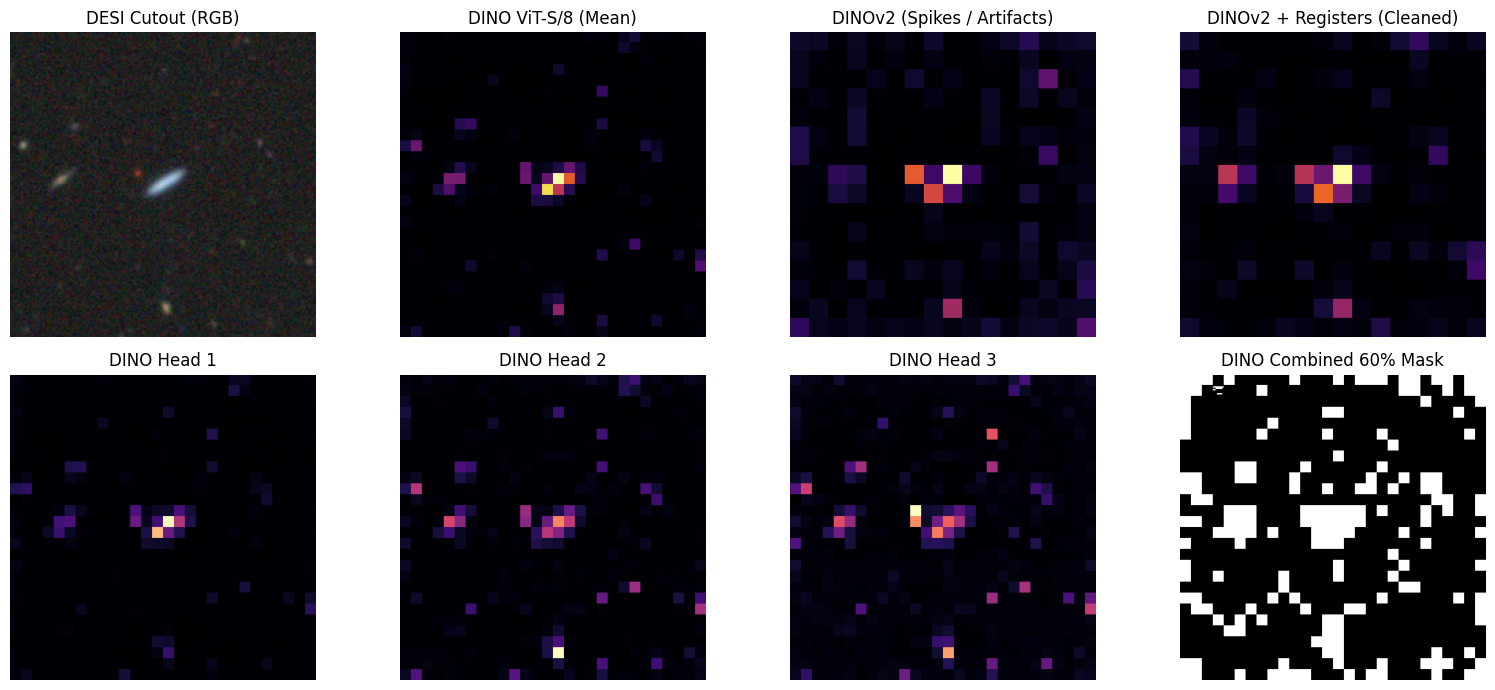

--- Galaxy Sample 6 ---


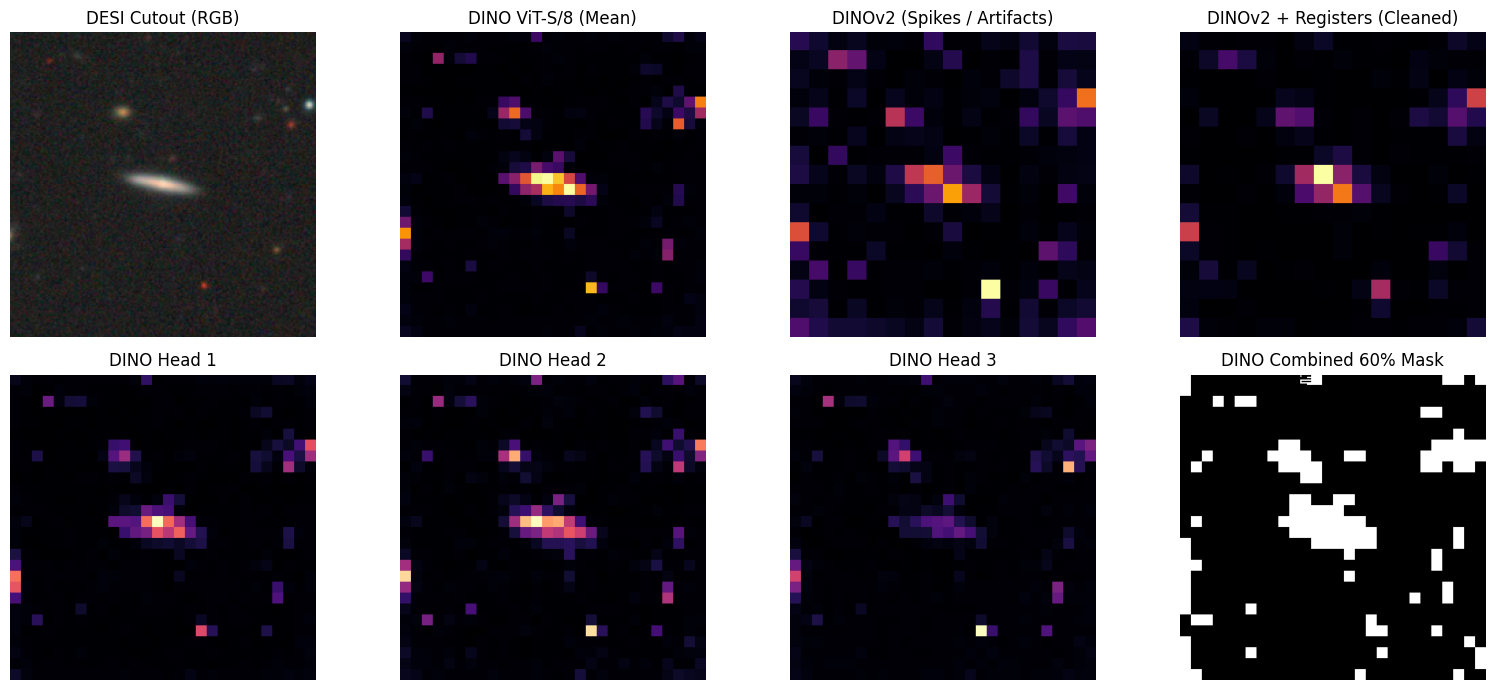

--- Galaxy Sample 7 ---


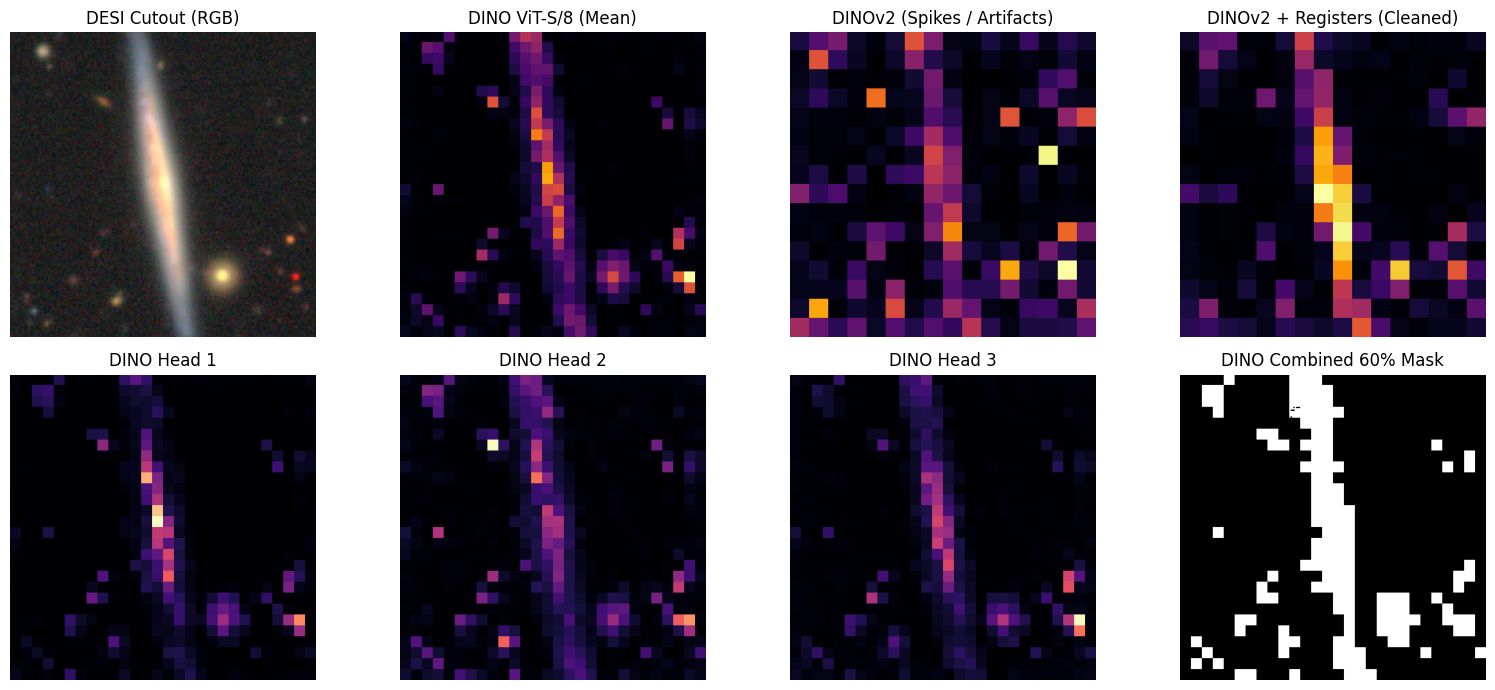

--- Galaxy Sample 8 ---


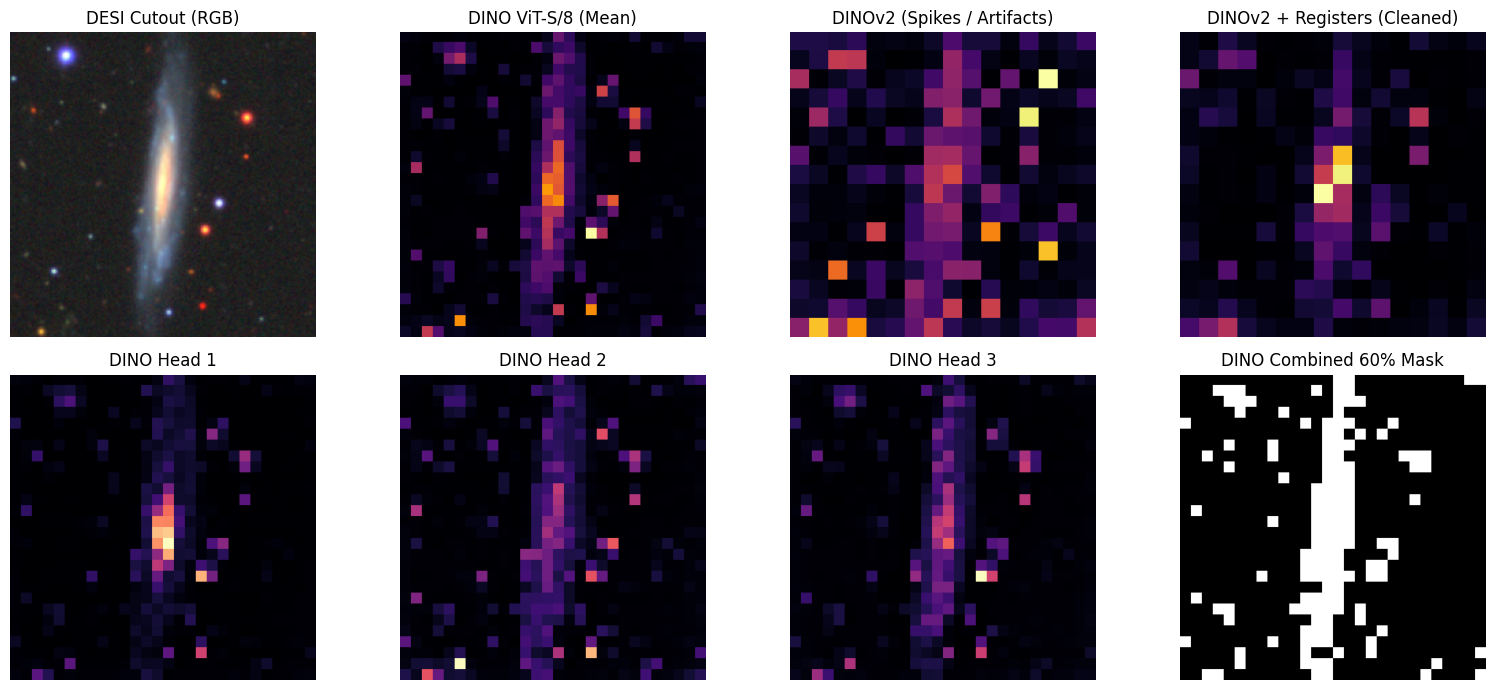

In [15]:
import numpy as np
from datasets import load_dataset

# 1. Load sample galaxies from the gz10 dataset (used in Task B)
print("Loading galaxy samples from gz10...")
dataset = load_dataset("MultimodalUniverse/gz10", split="train", streaming=True)
sample_galaxies = []

# Collect 8 diverse galaxy cutouts
for sample in dataset.take(8):
    img = sample["rgb_image"]  # PIL image or numpy array  # PIL image or numpy array
    if hasattr(img, "convert"):
        img = img.convert("RGB")
    sample_galaxies.append(img)

# 2. Side-by-side DINO vs DINOv2 vs DINOv2+Registers visualizer
def visualize_dino_comparison(image_tensor, attn_dino, attn_v2, attn_v2_reg, mask_dino):
    """
    Compares:
      Row 1: RGB Cutout | DINO ViT-S/8 (Mean attention across heads) | DINO ViT-S/8 60% Mask
      Row 2: DINOv2 ViT-S/14 Mean Attention (note artifact spikes) | DINOv2 + Registers Mean Attention
      Row 3: DINO ViT-S/8 individual heads (Heads 1 to 6)
    """
    # De-normalize image for visualization
    inv_normalize = transforms.Normalize(
        mean=[-0.485 / 0.229, -0.456 / 0.224, -0.406 / 0.225],
        std=[1 / 0.229, 1 / 0.224, 1 / 0.225]
    )
    rgb_disp = inv_normalize(image_tensor[0]).permute(1, 2, 0).clamp(0, 1).cpu().numpy()

    fig = plt.figure(figsize=(16, 7))

    # --- Top Row: Comparison ---
    ax1 = plt.subplot(2, 4, 1)
    ax1.imshow(rgb_disp)
    ax1.set_title("DESI Cutout (RGB)")
    ax1.axis('off')

    ax2 = plt.subplot(2, 4, 2)
    ax2.imshow(attn_dino.mean(dim=0).cpu().numpy(), cmap='inferno')
    ax2.set_title("DINO ViT-S/8 (Mean)")
    ax2.axis('off')

    ax3 = plt.subplot(2, 4, 3)
    ax3.imshow(attn_v2.mean(dim=0).cpu().numpy(), cmap='inferno')
    ax3.set_title("DINOv2 (Spikes / Artifacts)")
    ax3.axis('off')

    ax4 = plt.subplot(2, 4, 4)
    ax4.imshow(attn_v2_reg.mean(dim=0).cpu().numpy(), cmap='inferno')
    ax4.set_title("DINOv2 + Registers (Cleaned)")
    ax4.axis('off')

    # --- Bottom Row: Individual DINO ViT-S/8 Heads & Combined Mask ---
    composite_mask = torch.max(mask_dino, dim=0)[0].cpu().numpy()

    # 3 representative heads + combined mask
    for i in range(3):
        ax = plt.subplot(2, 4, 5 + i)
        ax.imshow(attn_dino[i].cpu().numpy(), cmap='magma')
        ax.set_title(f"DINO Head {i + 1}")
        ax.axis('off')

    ax_mask = plt.subplot(2, 4, 8)
    ax_mask.imshow(composite_mask, cmap='gray')
    ax_mask.set_title("DINO Combined 60% Mask")
    ax_mask.axis('off')

    plt.tight_layout()
    plt.show()

# 3. Execution Loop across the galaxy samples
transform_pipe = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

print("Running Task A attention inference...")
with torch.no_grad():
    for idx, gal_img in enumerate(sample_galaxies):
        x = transform_pipe(gal_img).unsqueeze(0)

        # 1. DINO ViT-S/8 attention & naive masks
        attn_s8 = get_dino_vits8_attention(dino_vits8, x)
        masks_s8 = threshold_mask_per_head(attn_s8, threshold=0.6)

        # 2. DINOv2 without vs with registers
        attn_v2 = get_dinov2_attention(dinov2_vits14, x)
        attn_v2_reg = get_dinov2_attention(dinov2_vits14_reg, x)

        print(f"--- Galaxy Sample {idx + 1} ---")
        visualize_dino_comparison(x, attn_s8, attn_v2, attn_v2_reg, masks_s8)